In [ ]:
# STEP 0: Install libraries (takes about 1 minute)
!pip install -q wordcloud xgboost networkx nltk kafka-python pyspark==3.5.1 kagglehub streamlit

# Import libraries
import os, sys, re, json, time, glob, threading
from collections import Counter
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Project folders ("artifacts" = files used later by the dashboard)
PROJECT = "/content/sentiment_project"; ART = PROJECT + "/artifacts"
os.makedirs(ART, exist_ok=True); os.chdir(PROJECT); sys.path.insert(0, PROJECT)

# Settings (use SAMPLE = 8000 for a quick test run)
SEED, SAMPLE = 42, None
ORDER = ["Negative", "Neutral", "Positive"]
COLORS = {"Negative": "#c0392b", "Neutral": "#8a8f98", "Positive": "#2e8b57"}
LABEL2ID = {"Negative": 0, "Neutral": 1, "Positive": 2}
ID2LABEL = {0: "Negative", 1: "Neutral", 2: "Positive"}
np.random.seed(SEED)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.0/317.0 MB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.5/200.5 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 614.2/614.2 kB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 48.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.


In [ ]:
# STEP 1: LOAD DATASET (Kaggle: Coronavirus tweets NLP - Text Classification)
def find_file(name):
    for root in ("/content", os.path.expanduser("~/.cache/kagglehub")):
        hits = glob.glob(f"{root}/**/{name}", recursive=True)
        if hits: return hits[0]

if find_file("Corona_NLP_train.csv") is None:          # try automatic download
    try:
        import kagglehub
        kagglehub.dataset_download("datatattle/covid-19-nlp-text-classification")
    except Exception as e:
        print("Download failed:", e)
if find_file("Corona_NLP_train.csv") is None:          # otherwise upload both CSV files by hand
    from google.colab import files
    files.upload()

train_raw = pd.read_csv(find_file("Corona_NLP_train.csv"), encoding="latin-1")   # file is not utf-8
test_raw = pd.read_csv(find_file("Corona_NLP_test.csv"), encoding="latin-1")

# Explore the raw data
print("Train:", train_raw.shape, "| Unseen test:", test_raw.shape)
display(train_raw.head(3))
print("Missing values:\n", train_raw.isna().sum().to_string())
print("\nLabels:\n", train_raw["Sentiment"].value_counts().to_string())
print("\nDuplicate tweets:", train_raw["OriginalTweet"].duplicated().sum())

Using Colab cache for faster access to the 'covid-19-nlp-text-classification' dataset.


Saving Corona_NLP_test.csv to Corona_NLP_test.csv
Saving Corona_NLP_train.csv to Corona_NLP_train.csv
Train: (41157, 6) | Unseen test: (3798, 6)


,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
0,3799,48751,London,16-03-2020,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,Neutral
1,3800,48752,UK,16-03-2020,advice Talk to your neighbours family to excha...,Positive
2,3801,48753,Vagabonds,16-03-2020,Coronavirus Australia: Woolworths to give elde...,Positive


Missing values:
 UserName            0
ScreenName          0
Location         8590
TweetAt             0
OriginalTweet       0
Sentiment           0

Labels:
 Sentiment
Positive              11422
Negative               9917
Neutral                7713
Extremely Positive     6624
Extremely Negative     5481

Duplicate tweets: 0


In [ ]:
%%writefile preprocess.py
"""
preprocess.py  -  shared text-cleaning module
---------------------------------------------
The SAME function is used in:
  * the Colab notebook (training, Kafka consumer, Spark)
  * the Streamlit dashboard (live predictions)
Using one function everywhere guarantees that training data and new
posts are cleaned in exactly the same way.
"""
import re
import html
from functools import lru_cache

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import TweetTokenizer

# ---- one-time NLTK resource download (quiet, safe to call many times) ----
for _res in ("stopwords", "wordnet", "omw-1.4"):
    try:
        nltk.download(_res, quiet=True)
    except Exception:
        pass

# ---- regular expressions (compiled once for speed) ----
URL_RE      = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE  = re.compile(r"@\w+")
HASHTAG_RE  = re.compile(r"#(\w+)")
NON_ALPHA   = re.compile(r"[^a-z\s]")
MULTISPACE  = re.compile(r"\s+")

# ---- stop words: keep negations, they flip the meaning of a sentence ----
# "not good" and "good" are opposite sentiments, so we must NOT delete "not".
_NEGATIONS = {"no", "nor", "not", "never", "none", "nothing", "neither", "cannot"}
STOP_WORDS = set(stopwords.words("english")) - _NEGATIONS
# very short leftovers created by contractions ("it's" -> "it s")
STOP_WORDS |= {"amp", "rt", "via"}

_tokenizer  = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
_lemmatizer = WordNetLemmatizer()

# WordNet occasionally mangles a word ("scared" -> "scar", "pass" -> "pas").
# "scared" is an important negative-emotion word, so we protect it.
_LEMMA_EXCEPTIONS = {"scared": "scared", "pass": "pass"}


@lru_cache(maxsize=200_000)
def _lemma(word: str) -> str:
    """Lemmatize a word (cached, because the same words repeat a lot).
    First as a noun (prices -> price), then as a verb (buying -> buy)."""
    if word in _LEMMA_EXCEPTIONS:
        return _LEMMA_EXCEPTIONS[word]
    return _lemmatizer.lemmatize(_lemmatizer.lemmatize(word), pos="v")


def extract_hashtags(text: str):
    """Return the list of lower-case hashtags of a raw post (without '#')."""
    return [h.lower() for h in HASHTAG_RE.findall(str(text))]


def preprocess_text(text: str, return_tokens: bool = False):
    """
    Full cleaning pipeline for one social media post.

    1. lower-case + decode HTML entities (&amp; -> &)
    2. remove URLs and @mentions
    3. keep the WORD of a hashtag (#lockdown -> lockdown)
    4. expand contractions (don't -> do not)
    5. remove special characters, digits, emojis
    6. tokenize
    7. remove stop words (but keep negations)
    8. lemmatize
    """
    if not isinstance(text, str):
        return [] if return_tokens else ""

    text = html.unescape(text).lower()
    text = text.replace("\u2019", "'").replace("\u2018", "'")   # curly quotes
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = HASHTAG_RE.sub(r"\1", text)

    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"n't\b", " not", text)

    text = NON_ALPHA.sub(" ", text)
    text = MULTISPACE.sub(" ", text).strip()

    tokens = _tokenizer.tokenize(text)
    tokens = [t for t in tokens if len(t) > 1 and t not in STOP_WORDS]
    tokens = [_lemma(t) for t in tokens]

    return tokens if return_tokens else " ".join(tokens)

Writing preprocess.py


In [ ]:
# STEP 2: DATA PREPROCESSING - clean text and prepare labels
from preprocess import preprocess_text, extract_hashtags

# Merge 5 labels into 3
MERGE = {"Extremely Negative": "Negative", "Negative": "Negative", "Neutral": "Neutral",
         "Positive": "Positive", "Extremely Positive": "Positive"}

def prepare(raw):
    d = raw.rename(columns={"OriginalTweet": "text", "Sentiment": "raw_label", "TweetAt": "date"})
    d = d.dropna(subset=["text"]).drop_duplicates(subset="text")
    d["date"] = pd.to_datetime(d["date"], format="%d-%m-%Y")
    d["hashtags"] = d["text"].apply(extract_hashtags)
    d["tokens"] = d["text"].apply(lambda t: preprocess_text(t, return_tokens=True))   # cleaned word list
    d["clean_text"] = d["tokens"].apply(" ".join)
    d["sentiment"] = d["raw_label"].map(MERGE)
    d["label"] = d["sentiment"].map(LABEL2ID)
    d = d[d["tokens"].str.len() > 0]                                                   # drop empty tweets
    return d.reset_index(drop=True)

df = prepare(train_raw)
if SAMPLE: df = df.sample(SAMPLE, random_state=SEED).reset_index(drop=True)
test = prepare(test_raw)
test = test[~test["text"].isin(df["text"])].reset_index(drop=True)     # unseen data: never in training

print("Training tweets:", len(train_raw), "->", len(df), "| Unseen tweets:", len(test_raw), "->", len(test))
print(df["sentiment"].value_counts().to_string(), "\n")
for raw, clean in zip(df["text"].head(3), df["clean_text"].head(3)):
    print("RAW  :", raw[:150]); print("CLEAN:", clean[:150], "\n")

Training tweets: 41157 -> 41122 | Unseen tweets: 3798 -> 3796
sentiment
Positive    18044
Negative    15397
Neutral      7681 

RAW  : advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set u
CLEAN: advice talk neighbour family exchange phone number create contact list phone number neighbour school employer chemist gp set online shop account poss  

RAW  : Coronavirus Australia: Woolworths to give elderly, disabled dedicated shopping hours amid COVID-19 outbreak https://t.co/bInCA9Vp8P
CLEAN: coronavirus australia woolworth give elderly disable dedicate shop hour amid covid outbreak 



PLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you 
CLEAN: food stock not one empty please not panic enough food everyone not take need stay calm stay safe covid france covid covid coronavirus confinement conf 



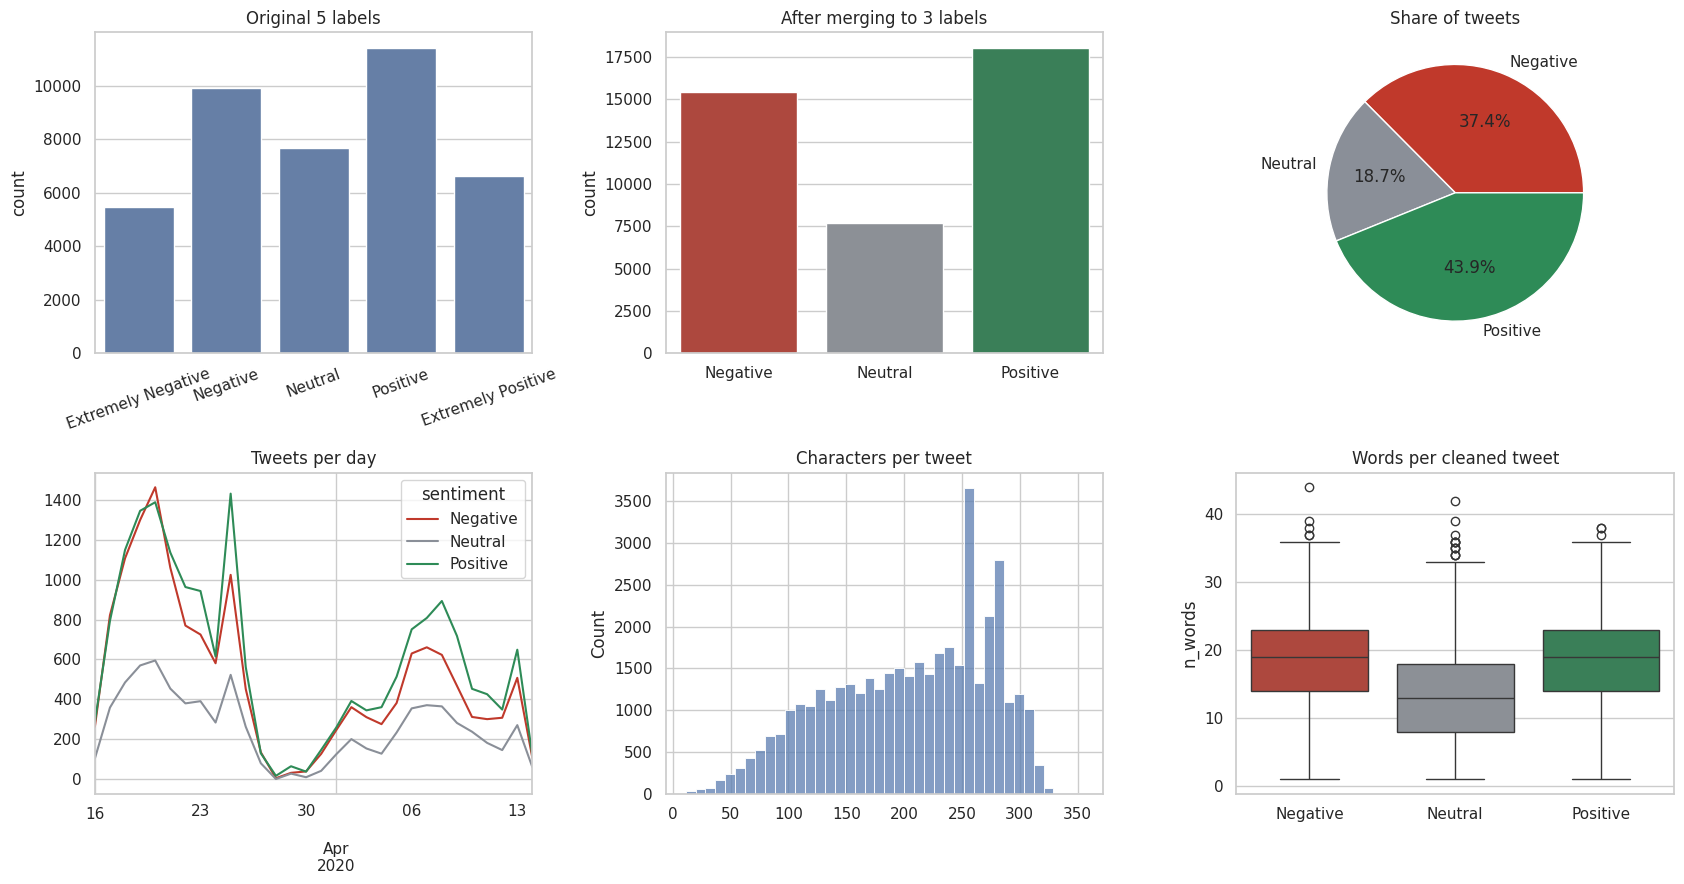

Observation 1 - class share (%): {'Negative': 37.4, 'Neutral': 18.7, 'Positive': 43.9}
Observation 2 - busiest day: 2020-03-20 | quietest day: 2020-03-28
Observation 3 - median words per tweet: {'Negative': 19.0, 'Neutral': 13.0, 'Positive': 19.0}


In [ ]:
# STEP 2b: EDA - sentiment distribution, tweets per day, tweet length
df["n_words"] = df["tokens"].str.len()
daily_counts = df.groupby(["date", "sentiment"]).size().unstack(fill_value=0)[ORDER]

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.countplot(data=df, x="raw_label", order=list(MERGE), color="#5b7db1", ax=ax[0, 0])
ax[0, 0].set_title("Original 5 labels"); ax[0, 0].tick_params(axis="x", rotation=20)
sns.countplot(data=df, x="sentiment", order=ORDER, palette=COLORS, ax=ax[0, 1]); ax[0, 1].set_title("After merging to 3 labels")
ax[0, 2].pie(df["sentiment"].value_counts()[ORDER], labels=ORDER, autopct="%1.1f%%", colors=list(COLORS.values()))
ax[0, 2].set_title("Share of tweets")
daily_counts.plot(ax=ax[1, 0], color=list(COLORS.values())); ax[1, 0].set_title("Tweets per day")
sns.histplot(df["text"].str.len(), bins=40, ax=ax[1, 1], color="#5b7db1"); ax[1, 1].set_title("Characters per tweet")
sns.boxplot(data=df, x="sentiment", y="n_words", order=ORDER, palette=COLORS, ax=ax[1, 2]); ax[1, 2].set_title("Words per cleaned tweet")
for a in ax.ravel(): a.set_xlabel("")
plt.tight_layout(); plt.show()

share = df["sentiment"].value_counts(normalize=True)[ORDER] * 100
print("Observation 1 - class share (%):", share.round(1).to_dict())
print("Observation 2 - busiest day:", daily_counts.sum(axis=1).idxmax().date(), "| quietest day:", daily_counts.sum(axis=1).idxmin().date())
print("Observation 3 - median words per tweet:", df.groupby("sentiment")["n_words"].median()[ORDER].to_dict())

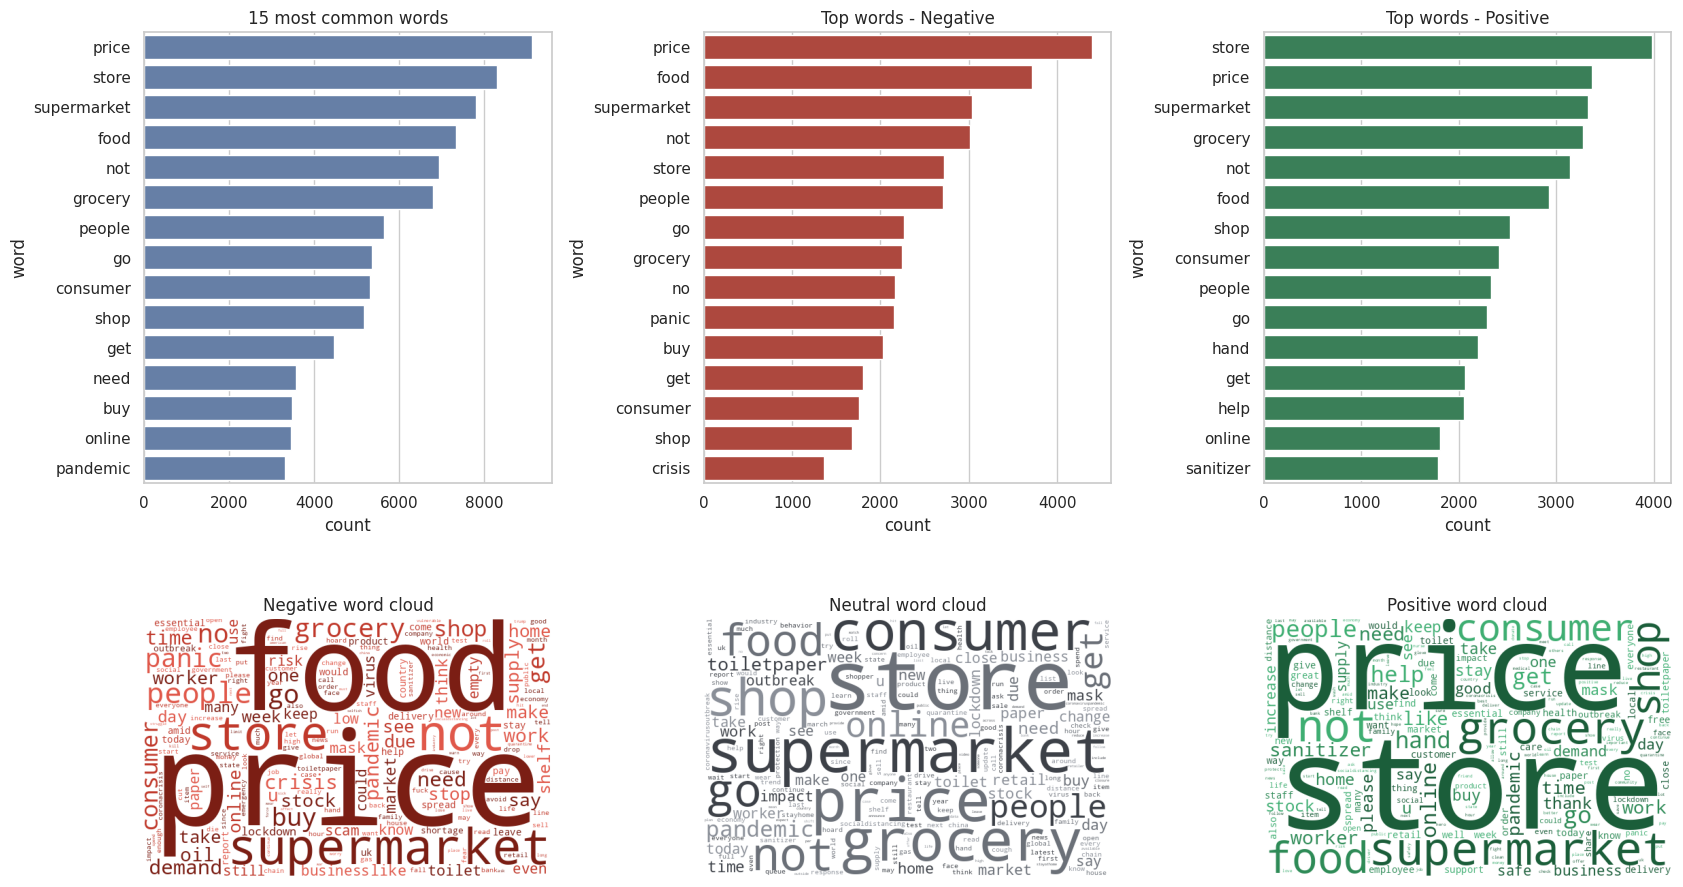

Distinctive words for Negative: threaten, blame, crude, attack, arrest, dead, worst, hell
Distinctive words for Neutral : toiletpaperpanic, toiletpapercrisis, property, toiletpaper, research, behavior, trend, enter
Distinctive words for Positive: bonus, enjoy, best, safely, happy, amaze, friendly, appreciate
Top hashtags: [('coronavirus', 15986), ('covid19', 4841), ('covid_19', 3165), ('covid2019', 1673), ('covid', 1632), ('toiletpaper', 1614), ('socialdistancing', 938), ('coronacrisis', 767)]


In [ ]:
# STEP 2c: EDA - word frequency, most common words, word clouds
from wordcloud import WordCloud
HIDE = {"covid", "coronavirus", "corona"}          # these words are in almost every tweet

def count_words(token_lists):
    c = Counter()
    for tokens in token_lists: c.update(w for w in tokens if w not in HIDE)
    return c

all_words = count_words(df["tokens"])
class_words = {s: count_words(df[df["sentiment"] == s]["tokens"]) for s in ORDER}

fig, ax = plt.subplots(2, 3, figsize=(17, 10))
top = pd.DataFrame(all_words.most_common(15), columns=["word", "count"])
sns.barplot(data=top, y="word", x="count", color="#5b7db1", ax=ax[0, 0]); ax[0, 0].set_title("15 most common words")
for a, s in zip(ax[0, 1:], ["Negative", "Positive"]):
    t = pd.DataFrame(class_words[s].most_common(15), columns=["word", "count"])
    sns.barplot(data=t, y="word", x="count", color=COLORS[s], ax=a); a.set_title(f"Top words - {s}")
from matplotlib.colors import ListedColormap
shades = {"Negative": ["#7b1e14", "#c0392b", "#e0584a"], "Neutral": ["#3d4148", "#6b7078", "#8a8f98"], "Positive": ["#1b5e3a", "#2e8b57", "#3fae72"]}
for a, s in zip(ax[1], ORDER):
    cloud = WordCloud(width=600, height=380, background_color="white", colormap=ListedColormap(shades[s]), random_state=SEED).generate_from_frequencies(class_words[s])
    a.imshow(cloud); a.axis("off"); a.set_title(f"{s} word cloud")
plt.tight_layout(); plt.show()

# Words that are much more common in one sentiment than overall
total = sum(all_words.values())
for s in ORDER:
    t = sum(class_words[s].values())
    lift = {w: (n / t) / (all_words[w] / total) for w, n in class_words[s].items() if n >= 50}
    print(f"Distinctive words for {s:8s}:", ", ".join(sorted(lift, key=lift.get, reverse=True)[:8]))
tags = Counter(t for h in df["hashtags"] for t in h)
print("Top hashtags:", tags.most_common(8))

In [ ]:
# STEP 3: MODEL SELECTION - split data (80/20) and turn text into TF-IDF numbers
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)
y_train, y_test = y_train.values, y_test.values

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)   # words + word pairs
X_train = tfidf.fit_transform(X_train_text)       # learn vocabulary from training data only
X_test = tfidf.transform(X_test_text)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (32897, 5000) | Test: (8225, 5000)


trained Logistic Regression
trained Naive Bayes
trained Random Forest
trained XGBoost


,Model,Accuracy,Precision,Recall,F1-Score,Train Time (s)
0,Logistic Regression,0.7854,0.8008,0.7854,0.7894,6.1024
1,XGBoost,0.7312,0.7675,0.7312,0.7384,157.7375
2,Random Forest,0.7334,0.7438,0.7334,0.7358,48.7710
3,Naive Bayes,0.6830,0.6863,0.6830,0.6681,0.0141


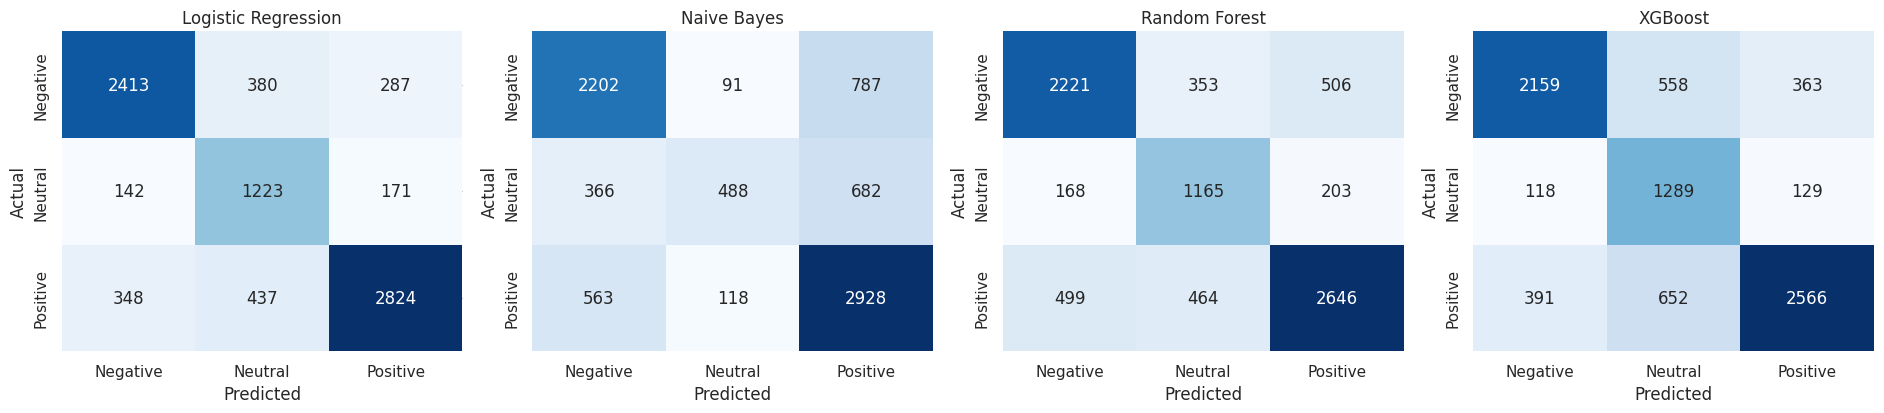

Best model: Logistic Regression 

              precision    recall  f1-score   support

    Negative      0.831     0.783     0.807      3080
     Neutral      0.600     0.796     0.684      1536
    Positive      0.860     0.782     0.820      3609

    accuracy                          0.785      8225
   macro avg      0.764     0.787     0.770      8225
weighted avg      0.801     0.785     0.789      8225



In [ ]:
# STEP 4 + 5: MODEL BUILDING and EVALUATION - 4 machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=2.0, class_weight="balanced", random_state=SEED),
    "Naive Bayes": MultinomialNB(alpha=0.3),
    "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.6,
                             tree_method="hist", eval_metric="mlogloss", n_jobs=-1, random_state=SEED),
}

def get_scores(name, pred, seconds):                  # Accuracy, Precision, Recall, F1 (weighted over the 3 classes)
    return {"Model": name, "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, average="weighted"),
            "Recall": recall_score(y_test, pred, average="weighted"),
            "F1-Score": f1_score(y_test, pred, average="weighted"), "Train Time (s)": seconds}

predictions, rows = {}, []
for name, model in models.items():
    start = time.time()
    if name == "XGBoost": model.fit(X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train))
    else: model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    rows.append(get_scores(name, predictions[name], time.time() - start))
    print("trained", name)

results = pd.DataFrame(rows).sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(results.round(4))

# Confusion matrices (rows = true class, columns = predicted class)
fig, ax = plt.subplots(1, 4, figsize=(19, 4.3))
for a, name in zip(ax, models):
    sns.heatmap(confusion_matrix(y_test, predictions[name]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=ORDER, yticklabels=ORDER)
    a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.show()

# Best classic model = highest F1
best_name = results.iloc[0]["Model"]; best_model = models[best_name]
print("Best model:", best_name, "\n"); print(classification_report(y_test, predictions[best_name], target_names=ORDER, digits=3))

Epoch 1/8
232/232 - 30s - 128ms/step - accuracy: 0.6360 - loss: 0.8132 - val_accuracy: 0.8033 - val_loss: 0.5418
Epoch 2/8
232/232 - 24s - 102ms/step - accuracy: 0.8540 - loss: 0.4296 - val_accuracy: 0.8131 - val_loss: 0.5207
Epoch 3/8
232/232 - 24s - 102ms/step - accuracy: 0.9004 - loss: 0.3128 - val_accuracy: 0.8112 - val_loss: 0.5424
Epoch 4/8
232/232 - 25s - 108ms/step - accuracy: 0.9185 - loss: 0.2589 - val_accuracy: 0.8049 - val_loss: 0.6057


,Model,Accuracy,Precision,Recall,F1-Score,Train Time (s)
0,LSTM,0.8151,0.8161,0.8151,0.8152,105.2612
1,Logistic Regression,0.7854,0.8008,0.7854,0.7894,6.1024
2,XGBoost,0.7312,0.7675,0.7312,0.7384,157.7375
3,Random Forest,0.7334,0.7438,0.7334,0.7358,48.7710
4,Naive Bayes,0.6830,0.6863,0.6830,0.6681,0.0141


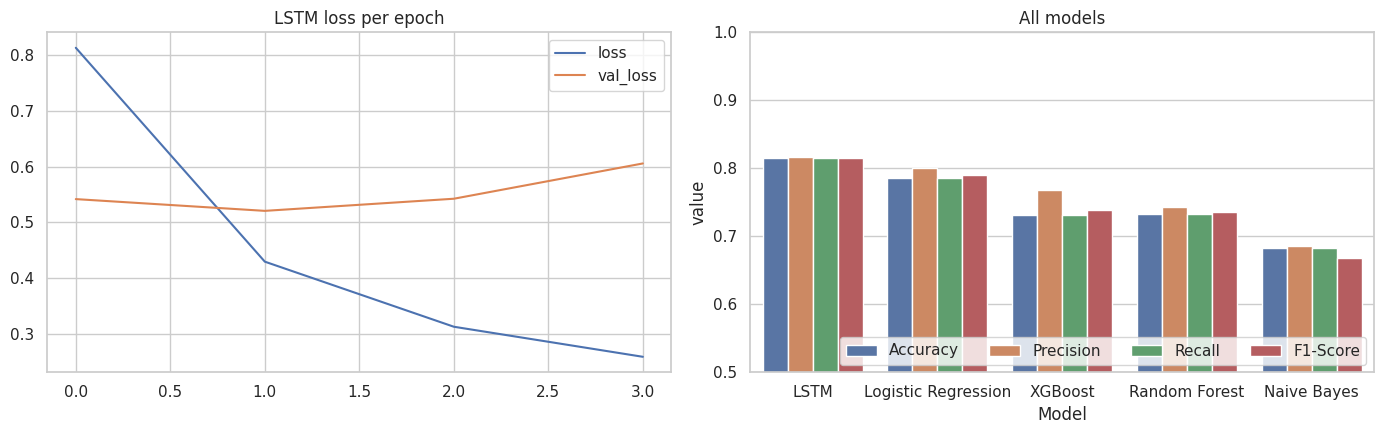

In [ ]:
# DEEP LEARNING: bidirectional LSTM (reads the tweet word by word)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
tf.random.set_seed(SEED)

# Words -> numbers (0 = padding, 1 = unknown word)
train_tokens = [t.split() for t in X_train_text]
vocab = {w: i + 2 for i, (w, _) in enumerate(Counter(w for t in train_tokens for w in t).most_common(19998))}
MAX_LEN = int(np.percentile([len(t) for t in train_tokens], 95))

def to_numbers(texts):
    out = np.zeros((len(texts), MAX_LEN), dtype="int32")
    for i, text in enumerate(texts):
        ids = [vocab.get(w, 1) for w in text.split()][:MAX_LEN]
        out[i, :len(ids)] = ids
    return out
X_train_seq, X_test_seq = to_numbers(X_train_text), to_numbers(X_test_text)

# Build the network
lstm = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(len(vocab) + 2, 64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.4),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax")])
lstm.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Train (stops early when validation loss stops improving)
weights = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)))
start = time.time()
history = lstm.fit(X_train_seq, y_train, validation_split=0.1, epochs=8, batch_size=128, class_weight=weights, verbose=2,
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
predictions["LSTM"] = lstm.predict(X_test_seq, verbose=0).argmax(axis=1)

# Compare LSTM with the classic models
all_results = pd.concat([results, pd.DataFrame([get_scores("LSTM", predictions["LSTM"], time.time() - start)])])
all_results = all_results.sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(all_results.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
pd.DataFrame(history.history)[["loss", "val_loss"]].plot(ax=ax[0]); ax[0].set_title("LSTM loss per epoch")
long = all_results.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1-Score"])
sns.barplot(data=long, x="Model", y="value", hue="variable", ax=ax[1]); ax[1].set_ylim(0.5, 1); ax[1].set_title("All models"); ax[1].legend(ncol=4, loc="lower right")
plt.tight_layout(); plt.show()

In [ ]:
# KAFKA: install Java + Kafka and start the broker (needs internet, about 2 minutes)
!apt-get -qq update > /dev/null 2>&1
!apt-get -qq install -y openjdk-17-jdk-headless > /dev/null 2>&1
!wget -q -nc https://archive.apache.org/dist/kafka/3.7.0/kafka_2.13-3.7.0.tgz -P /content
!tar -xzf /content/kafka_2.13-3.7.0.tgz -C /content
import subprocess
from kafka import KafkaProducer, KafkaConsumer
from kafka.admin import KafkaAdminClient, NewTopic
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

KAFKA, SERVER = "/content/kafka_2.13-3.7.0", "localhost:9092"
config = KAFKA + "/config/kraft/server.properties"
cluster_id = subprocess.check_output([KAFKA + "/bin/kafka-storage.sh", "random-uuid"], text=True).strip()
subprocess.run([KAFKA + "/bin/kafka-storage.sh", "format", "--ignore-formatted", "-t", cluster_id, "-c", config], check=True, capture_output=True)
kafka_proc = subprocess.Popen([KAFKA + "/bin/kafka-server-start.sh", config], stdout=open("kafka.log", "w"), stderr=subprocess.STDOUT)

admin = None
for _ in range(30):                                   # wait until the broker answers
    try: admin = KafkaAdminClient(bootstrap_servers=SERVER); break
    except Exception: time.sleep(2)
assert admin is not None, "Kafka did not start - see kafka.log"
print("Kafka is running")

ERROR:kafka.net.manager:Connection failed: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.net.connection:<KafkaConnection node_id=bootstrap-0 broker_version=unknown (disconnected)>: Connection lost: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.net.manager:Connection failed: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.net.connection:<KafkaConnection node_id=bootstrap-0 broker_version=unknown (disconnected)>: Connection lost: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.net.manager:Connection failed: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.net.connection:<KafkaConnection node_id=bootstrap-0 broker_version=unknown (disconnected)>: Connection lost: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.net.manager:Connection failed: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.net.connection:<KafkaConnection node_id=bootstrap-0 broker_version=unknown (disconnected)>: Connection lost: KafkaConnectionError: 111 ECONNREFUSED


Kafka is running


Created topic: tweets_1791104036
Tweets selected: 1200
Consumer subscribed.
batch  1:  466 tweets | running accuracy 78.5%
batch  2:  129 tweets | running accuracy 78.5%
batch  3:   25 tweets | running accuracy 77.9%
batch  4:    7 tweets | running accuracy 78.0%
batch  5:    2 tweets | running accuracy 78.1%
batch  6:    2 tweets | running accuracy 78.1%
batch  7:    1 tweets | running accuracy 78.2%
batch  8:    3 tweets | running accuracy 78.3%
batch  9:    2 tweets | running accuracy 78.2%
batch 10:    1 tweets | running accuracy 78.2%
batch 11:    2 tweets | running accuracy 78.1%
batch 12:    2 tweets | running accuracy 78.2%
batch 13:    2 tweets | running accuracy 78.1%
batch 14:    2 tweets | running accuracy 78.2%
batch 15:    2 tweets | running accuracy 78.2%
batch 16:    1 tweets | running accuracy 78.3%
batch 17:    1 tweets | running accuracy 78.3%
batch 18:    2 tweets | running accuracy 78.2%
batch 19:    3 tweets | running accuracy 78.2%
batch 20:    3 tweets | running

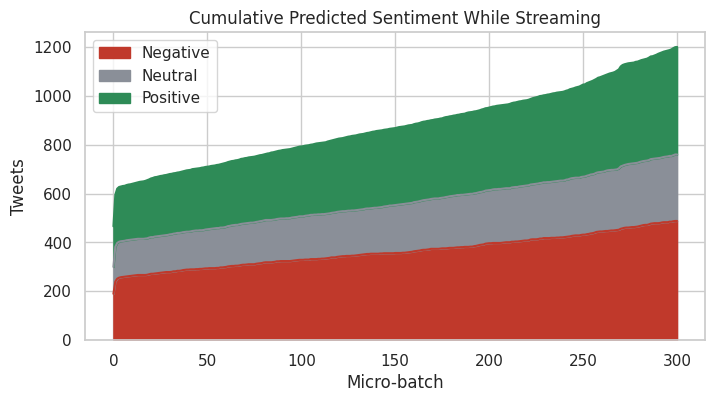

In [ ]:
# STREAMING SIMULATION: producer sends tweets to Kafka, consumer reads them in micro-batches and predicts sentiment

# =====================================================
# STREAMING SIMULATION
# =====================================================

TOPIC = f"tweets_{int(time.time())}"

# Create topic
try:
    admin.create_topics([
        NewTopic(
            name=TOPIC,
            num_partitions=1,
            replication_factor=1
        )
    ])
    print(f"Created topic: {TOPIC}")
except Exception as e:
    print(f"Topic creation warning: {e}")

# Give Kafka time to register the topic
time.sleep(5)

# =====================================================
# PRODUCER
# =====================================================

producer = KafkaProducer(
    bootstrap_servers=SERVER,
    value_serializer=lambda v: json.dumps(v).encode("utf-8")
)

def send_tweets(tweets, topic=TOPIC, delay=0.004):

    sent_count = 0

    for row in tweets.itertuples():

        producer.send(
            topic,
            {
                "text": row.text,
                "event_date": str(row.date.date()),
                "true_label": row.sentiment
            }
        )

        sent_count += 1
        time.sleep(delay)

    producer.flush()

    print(f"Sent {sent_count} tweets to Kafka.")

# =====================================================
# DATA TO STREAM
# =====================================================

N = min(1200, len(test))

if N == 0:
    raise ValueError("Test dataset is empty.")

stream_tweets = (
    test.sample(
        N,
        random_state=SEED
    )
    .sort_values("date")
)

print("Tweets selected:", N)

# =====================================================
# CONSUMER
# =====================================================

consumer = KafkaConsumer(
    bootstrap_servers=SERVER,
    auto_offset_reset="earliest",
    enable_auto_commit=False,
    consumer_timeout_ms=10000,
    value_deserializer=lambda b: json.loads(b.decode("utf-8"))
)

consumer.subscribe([TOPIC])

print("Consumer subscribed.")

# Allow subscription to complete
time.sleep(3)

# =====================================================
# START PRODUCER THREAD
# =====================================================

threading.Thread(
    target=send_tweets,
    args=(stream_tweets,),
    daemon=True
).start()

# Give producer a head start
time.sleep(2)

# =====================================================
# STREAM PROCESSING
# =====================================================

batches = []
received = []
correct = 0
score_time = 0.0

MAX_IDLE_BATCHES = 10
idle_batches = 0

while len(received) < N and idle_batches < MAX_IDLE_BATCHES:

    msgs = []

    polled = consumer.poll(
        timeout_ms=1000,
        max_records=500
    )

    for records in polled.values():
        for msg in records:
            msgs.append(msg.value)

    if len(msgs) == 0:
        idle_batches += 1
        continue

    idle_batches = 0

    start = time.time()

    pred = best_model.predict(
        tfidf.transform(
            [
                preprocess_text(m["text"])
                for m in msgs
            ]
        )
    )

    score_time += time.time() - start

    for m, p in zip(msgs, pred):
        m["predicted"] = ID2LABEL[int(p)]

    received.extend(msgs)

    correct += sum(
        m["predicted"] == m["true_label"]
        for m in msgs
    )

    c = Counter(
        m["predicted"]
        for m in msgs
    )

    batches.append({
        "batch": len(batches) + 1,
        "messages": len(msgs),
        **{
            s: c.get(s, 0)
            for s in ORDER
        }
    })

    running_accuracy = correct / len(received)

    print(
        f"batch {len(batches):>2}: "
        f"{len(msgs):>4} tweets | "
        f"running accuracy {running_accuracy:.1%}"
    )

consumer.close()

# =====================================================
# RESULTS
# =====================================================

stream_df = pd.DataFrame(batches)

stream_accuracy = (
    correct / len(received)
    if len(received) > 0
    else 0
)

stream_speed = (
    len(received) / score_time
    if score_time > 0
    else 0
)

print("\n" + "=" * 60)

if len(received) > 0:

    print(
        f"Processed {len(received)} tweets "
        f"in {len(batches)} micro-batches"
    )

    print(
        f"Streaming Accuracy : {stream_accuracy:.2%}"
    )

    print(
        f"Scoring Speed      : {stream_speed:,.0f} tweets/sec"
    )

    if not stream_df.empty:

        stream_df[ORDER].cumsum().plot.area(
            color=list(COLORS.values()),
            figsize=(8, 4),
            title="Cumulative Predicted Sentiment While Streaming"
        )

        plt.xlabel("Micro-batch")
        plt.ylabel("Tweets")
        plt.show()

else:

    print(
        "No tweets were consumed. "
        "Verify broker, topic, producer and consumer."
    )

In [ ]:
# SPARK (batch): process the cleaned data with Spark DataFrames
import pyspark
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType
scala = "2.13" if int(pyspark.__version__.split(".")[0]) >= 4 else "2.12"      # Kafka connector must match Spark version
connector = f"org.apache.spark:spark-sql-kafka-0-10_{scala}:{pyspark.__version__}"
spark = (SparkSession.builder.master("local[*]").appName("Sentiment")
         .config("spark.jars.packages", connector)
         .config("spark.sql.shuffle.partitions", "4")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

df[["date", "sentiment", "clean_text"]].to_csv(PROJECT + "/clean_tweets.csv", index=False)
sdf = spark.read.csv(PROJECT + "/clean_tweets.csv", header=True)
print("Spark rows:", sdf.count())
sdf.groupBy("sentiment").count().show()
words = sdf.select("sentiment", F.explode(F.split("clean_text", " ")).alias("word")).filter(~F.col("word").isin(*HIDE))
words.filter(F.col("sentiment") == "Negative").groupBy("word").count().orderBy(F.desc("count")).show(8)    # word count

Spark rows: 41122
+---------+-----+
|sentiment|count|
+---------+-----+
| Positive|18044|
|  Neutral| 7681|
| Negative|15397|
+---------+-----+

+-----------+-----+
|       word|count|
+-----------+-----+
|      price| 4396|
|       food| 3711|
|supermarket| 3042|
|        not| 3015|
|      store| 2724|
|     people| 2713|
|         go| 2269|
|    grocery| 2241|
+-----------+-----+
only showing top 8 rows



In [ ]:
# SPARK STRUCTURED STREAMING: Spark reads the Kafka topic directly and scores every micro-batch
TOPIC2 = f"tweets_spark_{int(time.time())}"
admin.create_topics([NewTopic(name=TOPIC2, num_partitions=1, replication_factor=1)])
schema = StructType([StructField("text", StringType()), StructField("event_date", StringType()), StructField("true_label", StringType())])

raw = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", SERVER).option("subscribe", TOPIC2)
       .option("startingOffsets", "earliest").option("maxOffsetsPerTrigger", 500).load())
tweets = raw.select(F.from_json(F.col("value").cast("string"), schema).alias("t")).select("t.*")

# Query 1: count tweets per true label
counts_query = tweets.groupBy("true_label").count().writeStream.outputMode("complete").format("memory").queryName("label_counts").start()

# Query 2: apply our model to each micro-batch
spark_results = []
def score_batch(batch_df, batch_id):
    pdf = batch_df.toPandas()
    if pdf.empty: return
    pdf["predicted"] = [ID2LABEL[int(p)] for p in best_model.predict(tfidf.transform(pdf["text"].apply(preprocess_text)))]
    spark_results.append({"batch": batch_id, "tweets": len(pdf), "accuracy": (pdf["predicted"] == pdf["true_label"]).mean()})
score_query = tweets.writeStream.foreachBatch(score_batch).option("checkpointLocation", f"{PROJECT}/ckpt_{int(time.time())}").start()

# Send tweets to the topic while Spark is listening
time.sleep(8)
threading.Thread(target=send_tweets, args=(test.sample(min(600, len(test)), random_state=7).sort_values("date"), TOPIC2, 0.02), daemon=True).start()
time.sleep(40)
counts_query.stop(); score_query.stop()

spark.sql("SELECT * FROM label_counts").show()
spark_df = pd.DataFrame(spark_results)
display(spark_df)
print("Spark scored", spark_df["tweets"].sum(), "tweets in", len(spark_df), "micro-batches")

Sent 600 tweets to Kafka.
+----------+-----+
|true_label|count|
+----------+-----+
|   Neutral|   88|
|  Positive|  259|
|  Negative|  253|
+----------+-----+



,batch,tweets,accuracy
0,1,1,1.000000
1,2,96,0.781250
2,3,85,0.776471
3,4,45,0.844444
4,5,27,0.703704
5,6,39,0.897436
6,7,30,0.733333
7,8,35,0.742857
8,9,28,0.714286
9,10,24,0.708333


Spark scored 600 tweets in 16 micro-batches


In [ ]:
# STEP 6: PREDICT - sentiment of a new post
def predict_sentiment(post):
    clean = preprocess_text(post)
    if not clean: return "Neutral", 0.0                   # nothing useful left after cleaning
    proba = best_model.predict_proba(tfidf.transform([clean]))[0]
    return ID2LABEL[int(best_model.classes_[proba.argmax()])], proba.max()

examples = ["So grateful to the nurses and doctors. Our community is amazing, stay safe everyone! #StayHome",
            "Empty shelves again. People are panic buying and it is a total disaster, I am scared.",
            "The government will publish the updated guidelines for supermarkets on Monday.",
            "Not good. Not good at all."]
for post in examples:
    label, conf = predict_sentiment(post)
    print(f"{label:9s} ({conf:.0%})  {post}")

# Type your own post
my_post = input("Type a post (or press Enter to skip): ")
if my_post.strip():
    label, conf = predict_sentiment(my_post)
    print("Predicted sentiment:", label, f"({conf:.0%} confident)")

Positive  (100%)  So grateful to the nurses and doctors. Our community is amazing, stay safe everyone! #StayHome
Negative  (100%)  Empty shelves again. People are panic buying and it is a total disaster, I am scared.
Neutral   (76%)  The government will publish the updated guidelines for supermarkets on Monday.
Negative  (50%)  Not good. Not good at all.
Type a post (or press Enter to skip): Overall Good Experience
Predicted sentiment: Positive (96% confident)


,Trend error,Average error
Sentiment,,
Negative,3.03,2.70
Neutral,1.59,2.00
Positive,2.23,1.69


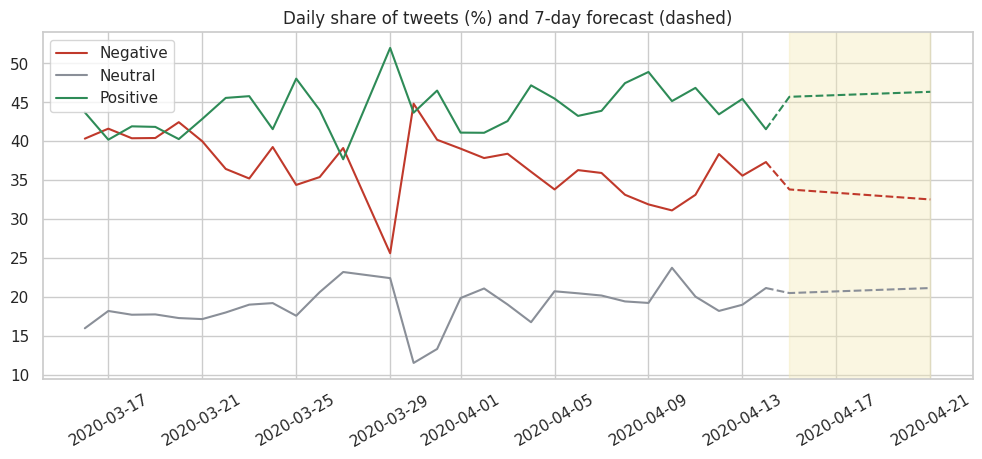

,Negative,Neutral,Positive
2020-04-15,33.8,20.5,45.7
2020-04-16,33.6,20.6,45.8
2020-04-17,33.4,20.7,45.9
2020-04-18,33.2,20.8,46.0
2020-04-19,32.9,20.9,46.1
2020-04-20,32.7,21.0,46.3
2020-04-21,32.5,21.1,46.4


Change per day (percentage points): {'Negative': np.float64(-0.21), 'Neutral': np.float64(0.11), 'Positive': np.float64(0.11)}


In [ ]:
# STEP 6b: PREDICT FUTURE TREND - daily sentiment share and a 7-day forecast (straight-line trend)
days = daily_counts[daily_counts.sum(axis=1) >= 30]                      # skip days with very few tweets
share = days.div(days.sum(axis=1), axis=0) * 100                        # % of tweets per day
n = len(share)

# Back-test: forecast the last 5 known days and compare with a simple "average" guess
rows = []
for s in ORDER:
    a, b = np.polyfit(np.arange(n - 5), share[s].values[:n - 5], 1)
    trend_error = np.abs(share[s].values[n - 5:] - (a * np.arange(n - 5, n) + b)).mean()
    average_error = np.abs(share[s].values[n - 5:] - share[s].values[:n - 5].mean()).mean()
    rows.append({"Sentiment": s, "Trend error": trend_error, "Average error": average_error})
backtest = pd.DataFrame(rows).set_index("Sentiment").round(2)
display(backtest)

# Real forecast for the next 7 days
future_days = pd.date_range(share.index[-1] + pd.Timedelta(days=1), periods=7)
forecast, slopes = pd.DataFrame(index=future_days), {}
for s in ORDER:
    a, b = np.polyfit(np.arange(n), share[s].values, 1)
    forecast[s] = a * np.arange(n, n + 7) + b; slopes[s] = a
forecast = forecast.clip(lower=0)
forecast = forecast.div(forecast.sum(axis=1), axis=0) * 100              # shares add up to 100 %

# Plot history + forecast
fig, ax = plt.subplots(figsize=(12, 4.5))
for s in ORDER:
    ax.plot(share.index, share[s], color=COLORS[s], label=s)
    ax.plot([share.index[-1], *forecast.index], [share[s].iloc[-1], *forecast[s]], color=COLORS[s], ls="--")
ax.axvspan(forecast.index[0], forecast.index[-1], color="#f3e9b5", alpha=0.4)
ax.set_title("Daily share of tweets (%) and 7-day forecast (dashed)"); ax.legend(); plt.xticks(rotation=30); plt.show()
display(forecast.round(1))
print("Change per day (percentage points):", {s: round(slopes[s], 2) for s in ORDER})
trend = pd.concat([share.reset_index().melt(id_vars="date", var_name="sentiment", value_name="percent").assign(kind="history"),
                   forecast.rename_axis("date").reset_index().melt(id_vars="date", var_name="sentiment", value_name="percent").assign(kind="forecast")])

Unseen tweets: 3796 | accuracy 0.771 | F1 0.775

              precision    recall  f1-score   support

    Negative      0.825     0.781     0.803      1633
     Neutral      0.567     0.765     0.651       617
    Positive      0.832     0.763     0.796      1546

    accuracy                          0.771      3796
   macro avg      0.741     0.770     0.750      3796
weighted avg      0.786     0.771     0.775      3796



,tweets,accuracy
conf_group,,
<50%,440,0.439
50-60%,588,0.588
60-70%,589,0.713
70-80%,601,0.835
>80%,1578,0.929


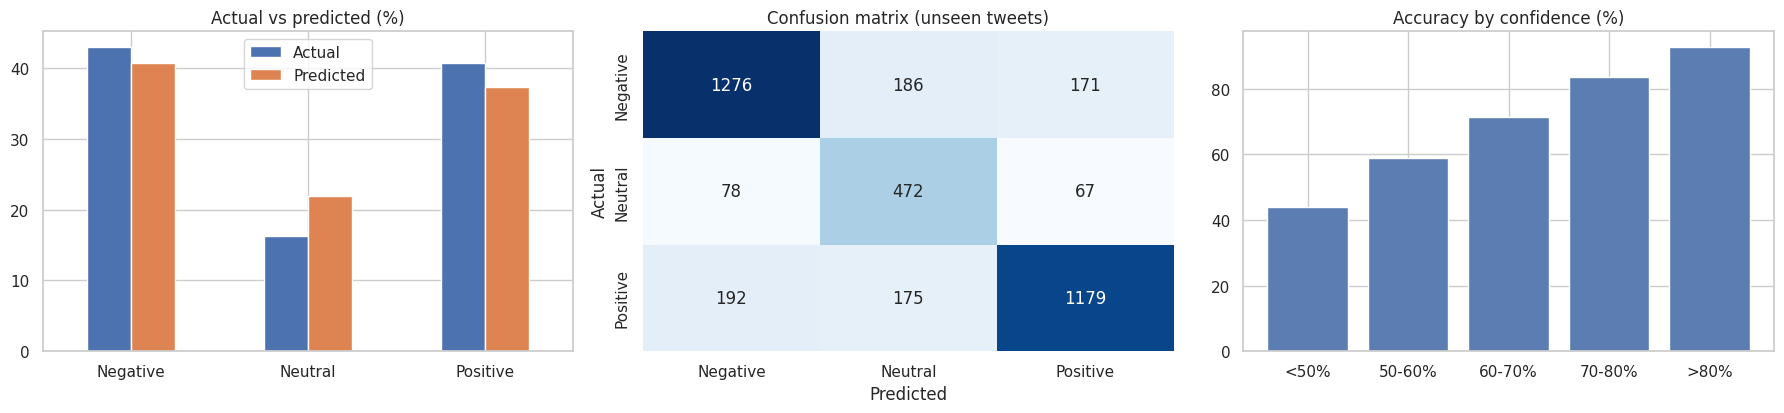

,text,sentiment,predicted,confidence
1355,I donÂt know why I was scared to go to the gr...,Positive,Negative,0.998566
1829,Felt a bit helpless about what I could do to h...,Negative,Positive,0.994568
2907,One grocery store in Helsinki has appealed to ...,Positive,Negative,0.992443
965,"We don't need to panic, and just so you unders...",Negative,Positive,0.983782
3046,With all of this panic shopping &amp; emptying...,Neutral,Negative,0.970931


In [ ]:
# STEP 7: ANALYZE PREDICTED RESULTS on the unseen tweets
proba = best_model.predict_proba(tfidf.transform(test["clean_text"]))
test["pred_label"] = best_model.classes_[proba.argmax(axis=1)]
test["predicted"] = test["pred_label"].map(ID2LABEL)
test["confidence"] = proba.max(axis=1)
test["correct"] = test["pred_label"] == test["label"]
unseen_acc = accuracy_score(test["label"], test["pred_label"])
unseen_f1 = f1_score(test["label"], test["pred_label"], average="weighted")
print(f"Unseen tweets: {len(test)} | accuracy {unseen_acc:.3f} | F1 {unseen_f1:.3f}\n")
print(classification_report(test["label"], test["pred_label"], target_names=ORDER, digits=3))

# Accuracy for different confidence levels
test["conf_group"] = pd.cut(test["confidence"], [0, .5, .6, .7, .8, 1.0], labels=["<50%", "50-60%", "60-70%", "70-80%", ">80%"])
by_conf = test.groupby("conf_group", observed=True).agg(tweets=("correct", "size"), accuracy=("correct", "mean"))
display(by_conf.round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
pd.DataFrame({"Actual": test["sentiment"].value_counts(normalize=True), "Predicted": test["predicted"].value_counts(normalize=True)}
             ).loc[ORDER].mul(100).plot.bar(ax=ax[0], rot=0); ax[0].set_title("Actual vs predicted (%)")
sns.heatmap(confusion_matrix(test["label"], test["pred_label"]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1], xticklabels=ORDER, yticklabels=ORDER)
ax[1].set_title("Confusion matrix (unseen tweets)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
ax[2].bar(by_conf.index.astype(str), by_conf["accuracy"] * 100, color="#5b7db1"); ax[2].set_title("Accuracy by confidence (%)")
plt.tight_layout(); plt.show()

# Most confident mistakes
display(test[~test["correct"]].sort_values("confidence", ascending=False)[["text", "sentiment", "predicted", "confidence"]].head(5))

Nodes: 40 | Edges: 150


,node,frequency,degree_centrality,pagerank
0,coronavirus,15879,1.0000,0.2800
1,covid19,4822,0.9744,0.1481
2,toiletpaper,1606,0.4872,0.0636
3,covid_19,3160,0.5641,0.0565
4,covid,1563,0.4103,0.0461
5,covid2019,1670,0.2821,0.0228
6,corona,418,0.2308,0.0193
7,stayhome,453,0.2564,0.0192
8,socialdistancing,936,0.2308,0.0192
9,coronavirusoutbreak,437,0.2051,0.0189


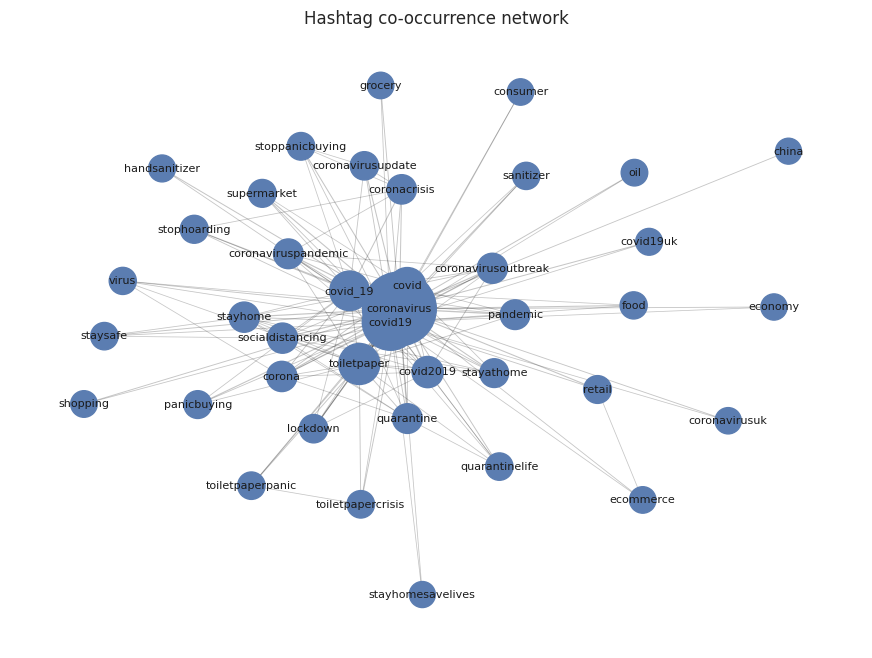

In [ ]:
# GRAPH ANALYTICS: hashtag co-occurrence network (two hashtags in one tweet = one edge)
import networkx as nx

top_tags = [t for t, _ in Counter(t for h in df["hashtags"] for t in set(h)).most_common(40)]
pair_counts = Counter()
for h in df["hashtags"]:
    pair_counts.update(combinations(sorted(set(h) & set(top_tags)), 2))

G = nx.Graph()
for (a, b), w in pair_counts.most_common(150):             # keep the 150 strongest connections
    if w >= 5: G.add_edge(a, b, weight=w)

# Degree Centrality and PageRank
net = pd.DataFrame({"node": list(G.nodes()),
                    "frequency": [sum(t in h for h in df["hashtags"]) for t in G.nodes()],
                    "degree_centrality": pd.Series(nx.degree_centrality(G)).reindex(G.nodes()).values,
                    "pagerank": pd.Series(nx.pagerank(G, weight="weight")).reindex(G.nodes()).values})
net = net.sort_values("pagerank", ascending=False).reset_index(drop=True)
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())
display(net.head(10).round(4))

# Draw the network (bigger node = higher PageRank)
pos = nx.spring_layout(G, seed=SEED, k=1.5 / np.sqrt(len(G)))
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G, pos, alpha=0.25, width=[0.5 + 4 * d["weight"] / max(w for _, _, w in G.edges(data="weight")) for _, _, d in G.edges(data=True)], ax=ax)
nx.draw_networkx_nodes(G, pos, node_size=[300 + 9000 * net.set_index("node").loc[n, "pagerank"] for n in G.nodes()], node_color="#5b7db1", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
ax.set_title("Hashtag co-occurrence network"); ax.axis("off"); plt.show()

In [ ]:
# SAVE everything the dashboard needs into the "artifacts" folder
import joblib
from sklearn.pipeline import Pipeline
joblib.dump(Pipeline([("tfidf", tfidf), ("clf", best_model)]), ART + "/sentiment_pipeline.joblib", compress=3)
json.dump({"id2label": {str(k): v for k, v in ID2LABEL.items()}}, open(ART + "/labels.json", "w"))
all_results.to_csv(ART + "/model_comparison.csv", index=False)
pd.DataFrame(confusion_matrix(y_test, predictions[best_name]), index=ORDER, columns=ORDER).rename_axis("Actual").reset_index().to_csv(ART + "/confusion_matrix.csv", index=False)
pd.concat([df["sentiment"], test["sentiment"]]).value_counts().loc[ORDER].rename_axis("Sentiment").reset_index(name="Count").to_csv(ART + "/sentiment_counts.csv", index=False)
pd.concat([pd.DataFrame(all_words.most_common(200), columns=["word", "count"]).assign(sentiment="All")] +
          [pd.DataFrame(class_words[s].most_common(200), columns=["word", "count"]).assign(sentiment=s) for s in ORDER]).to_csv(ART + "/word_freq.csv", index=False)
trend.to_csv(ART + "/trend.csv", index=False)
pd.DataFrame([(a, b, d["weight"]) for a, b, d in G.edges(data=True)], columns=["source", "target", "weight"]).to_csv(ART + "/network_edges.csv", index=False)
net.to_csv(ART + "/network_metrics.csv", index=False)
stream_df.to_csv(ART + "/streaming_results.csv", index=False)
best = results.iloc[0]
json.dump({"total_posts": len(df) + len(test), "best_model": best_name, "accuracy": best["Accuracy"], "f1": best["F1-Score"],
           "lstm_accuracy": all_results.loc[all_results["Model"] == "LSTM", "Accuracy"].iloc[0], "stream_accuracy": stream_accuracy},
          open(ART + "/metrics.json", "w"), indent=2)
open("requirements.txt", "w").write("streamlit\npandas\nnumpy\nscikit-learn\nxgboost\nnltk\nwordcloud\nmatplotlib\nseaborn\nnetworkx\njoblib\n")

try: spark.stop()                                          # stop Spark and Kafka, they are not needed any more
except Exception: pass
if kafka_proc.poll() is None: kafka_proc.terminate()
print("Saved:", sorted(os.listdir(ART)))

Saved: ['confusion_matrix.csv', 'labels.json', 'metrics.json', 'model_comparison.csv', 'network_edges.csv', 'network_metrics.csv', 'sentiment_counts.csv', 'sentiment_pipeline.joblib', 'streaming_results.csv', 'trend.csv', 'word_freq.csv']


In [ ]:
%%writefile streamlit_app.py
# Streamlit dashboard - run with:  streamlit run streamlit_app.py
# It only reads the files that the notebook saved in the "artifacts" folder.
import json
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns
import streamlit as st
from wordcloud import WordCloud
from preprocess import preprocess_text

st.set_page_config(page_title="Sentiment Dashboard", page_icon="📊", layout="wide")
ART = Path("artifacts")
ORDER = ["Negative", "Neutral", "Positive"]
COLORS = ["#c0392b", "#8a8f98", "#2e8b57"]

# Stop with a clear message if the notebook has not been run yet
if not (ART / "metrics.json").exists():
    st.error("Run the notebook first, then put the 'artifacts' folder next to this file.")
    st.stop()


@st.cache_resource
def load_model():
    return joblib.load(ART / "sentiment_pipeline.joblib")


def read(name):
    p = ART / name
    return pd.read_csv(p) if p.exists() else None


model = load_model()
metrics = json.load(open(ART / "metrics.json"))
id2label = {int(k): v for k, v in json.load(open(ART / "labels.json"))["id2label"].items()}

# ---------- Title and key numbers ----------
st.title("Social Media Sentiment Dashboard")
st.caption("Tweets -> Kafka stream -> Spark -> sentiment model -> dashboard")
c = st.columns(5)
c[0].metric("Posts analysed", f"{metrics['total_posts']:,}")
c[1].metric("Best classic model", metrics["best_model"])
c[2].metric("Accuracy", f"{metrics['accuracy']:.1%}")
c[3].metric("F1-score", f"{metrics['f1']:.1%}")
c[4].metric("LSTM accuracy", f"{metrics['lstm_accuracy']:.1%}")

tab1, tab2, tab3, tab4, tab5, tab6 = st.tabs(
    ["Overview", "Try a post", "Trends", "Word cloud", "Hashtag network", "Live stream"])

# ---------- Tab 1: sentiment distribution, model comparison, confusion matrix ----------
with tab1:
    left, right = st.columns(2)
    counts = read("sentiment_counts.csv")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.pie(counts["Count"], labels=counts["Sentiment"], colors=COLORS, autopct="%1.1f%%",
           wedgeprops={"width": 0.45, "edgecolor": "white"})
    ax.set_title("Sentiment distribution")
    left.pyplot(fig)
    plt.close(fig)
    right.subheader("Model comparison")
    right.dataframe(read("model_comparison.csv"), hide_index=True)
    cm = read("confusion_matrix.csv").set_index("Actual")
    fig, ax = plt.subplots(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"Confusion matrix - {metrics['best_model']}")
    right.pyplot(fig)
    plt.close(fig)

# ---------- Tab 2: predict a new post ----------
with tab2:
    text = st.text_area("Type or paste a social media post", height=100,
                        value="Grateful for the nurses and doctors. Stay safe everyone!")
    if st.button("Predict sentiment", type="primary"):
        clean = preprocess_text(text)
        if not clean:
            st.warning("No meaningful words left after cleaning, so the prediction is unreliable.")
        proba = pd.Series(model.predict_proba([clean])[0], index=[id2label[int(k)] for k in model.classes_])[ORDER]
        st.subheader(f"Prediction: {proba.idxmax()}  ({proba.max():.1%} confident)")
        st.bar_chart(proba)
        st.caption(f"Text seen by the model: {clean}")

# ---------- Tab 3: history and 7-day forecast ----------
with tab3:
    trend = read("trend.csv")
    if trend is not None:
        wide = trend.pivot(index="date", columns="sentiment", values="percent")[ORDER]
        st.line_chart(wide, color=COLORS)
        st.caption("Daily share of posts (%). The last 7 days are the forecast.")
        st.dataframe(trend[trend["kind"] == "forecast"].pivot(index="date", columns="sentiment", values="percent").round(1))

# ---------- Tab 4: word cloud ----------
with tab4:
    words = read("word_freq.csv")
    pick = st.radio("Show words from", ["All"] + ORDER, horizontal=True)
    sub = words[words["sentiment"] == pick]
    cloud = WordCloud(width=900, height=450, background_color="white").generate_from_frequencies(dict(zip(sub["word"], sub["count"])))
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.imshow(cloud)
    ax.axis("off")
    st.pyplot(fig)
    plt.close(fig)

# ---------- Tab 5: hashtag network ----------
with tab5:
    edges, nodes = read("network_edges.csv"), read("network_metrics.csv")
    G = nx.Graph()
    G.add_weighted_edges_from(edges.itertuples(index=False, name=None))
    pr = nodes.set_index("node")["pagerank"]
    fig, ax = plt.subplots(figsize=(9, 6))
    pos = nx.spring_layout(G, seed=42)
    nx.draw_networkx_edges(G, pos, alpha=0.25, ax=ax)
    nx.draw_networkx_nodes(G, pos, node_size=[300 + 9000 * pr[n] for n in G.nodes()], node_color="#5b7db1", ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.axis("off")
    st.pyplot(fig)
    plt.close(fig)
    st.dataframe(nodes.head(10)[["node", "frequency", "degree_centrality", "pagerank"]], hide_index=True)

# ---------- Tab 6: Kafka streaming results ----------
with tab6:
    stream = read("streaming_results.csv")
    if stream is not None:
        st.metric("Streaming accuracy", f"{metrics['stream_accuracy']:.1%}")
        st.area_chart(stream[ORDER].cumsum(), color=COLORS)
        st.caption("Cumulative posts per predicted sentiment, micro-batch by micro-batch.")

Writing streamlit_app.py


In [ ]:
# RUN THE DASHBOARD in Colab (public link through a Cloudflare tunnel), then zip the project
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared
import shutil
subprocess.Popen([sys.executable, "-m", "streamlit", "run", "streamlit_app.py", "--server.port", "8501", "--server.headless", "true"],
                 cwd=PROJECT, stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(8)
subprocess.Popen(["/content/cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"], stdout=open("cloudflared.log", "w"), stderr=subprocess.STDOUT)
for _ in range(45):
    time.sleep(1)
    link = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("cloudflared.log").read())
    if link: print("Open the dashboard here:", link.group(0)); break

# Zip the project so you can run it on your own computer:  pip install -r requirements.txt  then  streamlit run streamlit_app.py
shutil.rmtree("/content/pack", ignore_errors=True); os.makedirs("/content/pack/sentiment_project")
for f in ["streamlit_app.py", "preprocess.py", "requirements.txt"]: shutil.copy(f, "/content/pack/sentiment_project")
shutil.copytree(ART, "/content/pack/sentiment_project/artifacts")
from google.colab import files
files.download(shutil.make_archive("/content/sentiment_project", "zip", "/content/pack"))

ERROR:kafka.net.manager:Connection failed: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.net.connection:<KafkaConnection node_id=1 broker_version=(3, 7) (disconnected)>: Connection lost: KafkaConnectionError: 111 ECONNREFUSED
ERROR:kafka.cluster:Metadata refresh: failed KafkaConnectionError: 111 ECONNREFUSED


Open the dashboard here: https://quoted-cabinet-abc-dragon.trycloudflare.com


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# SUMMARY of key results (use these numbers in the report)
print("Best classic model:", best_name, "| LSTM F1:", round(all_results.loc[all_results["Model"] == "LSTM", "F1-Score"].iloc[0], 4))
print("Unseen tweets accuracy:", round(unseen_acc, 4), "| Kafka stream accuracy:", round(stream_accuracy, 4), "| Kafka speed:", round(stream_speed), "tweets/s")
print("Forecast change per day (pp):", {s: round(v, 2) for s, v in slopes.items()})
print("Top 3 hashtags by PageRank:", list(net["node"].head(3)))

Best classic model: Logistic Regression | LSTM F1: 0.8152
Unseen tweets accuracy: 0.7711 | Kafka stream accuracy: 0.7742 | Kafka speed: 609 tweets/s
Forecast change per day (pp): {'Negative': np.float64(-0.21), 'Neutral': np.float64(0.11), 'Positive': np.float64(0.11)}
Top 3 hashtags by PageRank: ['coronavirus', 'covid19', 'toiletpaper']
